# Linear Regression: Experience vs Salary Prediction

**Machine Learning Algorithm:** Simple Linear Regression  
**Learning Type:** Supervised Learning  
**Problem Type:** Linear Regression  
**Dataset:** Salary_Data_set.csv

Import libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

from sklearn.model_selection import train_test_split
from sklearn.linear_model    import LinearRegression
from sklearn.metrics         import mean_squared_error,mean_absolute_error,r2_score

print("All libraries are imported succesfully")


All libraries are imported succesfully


Load the Dataset

In [6]:


df=pd.read_csv(r"C:\Users\ASUS\OneDrive\Desktop\Aditya project\AI-ML-Algorithms\Datasets\Salary_Data_set.csv")

Inspect the dataset

In [24]:
print(df.head())
print(df.tail())

   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891
    YearsExperience  Salary
25              9.0  105582
26              9.5  116969
27              9.6  112635
28             10.3  122391
29             10.5  121872


In [18]:
print("The size of data set is ",df.size)
print("The number of column is ",df.shape[1])
print("The shape of row is ",df.shape[0])

The size of data set is  60
The number of column is  2
The shape of row is  30


In [35]:
print(df.columns.to_list())

['YearsExperience', 'Salary']


In [22]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes
None


In [21]:
print(df.describe())

       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000   65237.000000
75%           7.700000  100544.750000
max          10.500000  122391.000000


Check the missing  and duplicate  values

In [25]:
print(df.isnull().sum())

YearsExperience    0
Salary             0
dtype: int64


In [26]:
print(df.duplicated().sum())

0


Clean the dataset

In [7]:
df=df.rename(columns={
    "yearExperience":"Experience",
    "Salary":"Salary"
})

df.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [8]:
# copy the particular columns needed
df=df[["YearsExperience","Salary"]].copy()

# convert values to numeric except Nan
df["Salary"]=pd.to_numeric( df["Salary"] , errors="coerce")
df["YearsExperience"]=pd.to_numeric(df["YearsExperience"] , errors="coerce")

# drop Nan and duplicates
df=df.dropna()
df=df.drop_duplicates()

# reset index
df=df.reset_index(drop=True)

df.head()


,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [9]:
print("After cleaning number of values are : ", df.shape)
print("The missing number of values are :")
print(df.isna().sum())

After cleaning number of values are :  (30, 2)
The missing number of values are :
YearsExperience    0
Salary             0
dtype: int64


Exploratory Data Analysis (EDA)

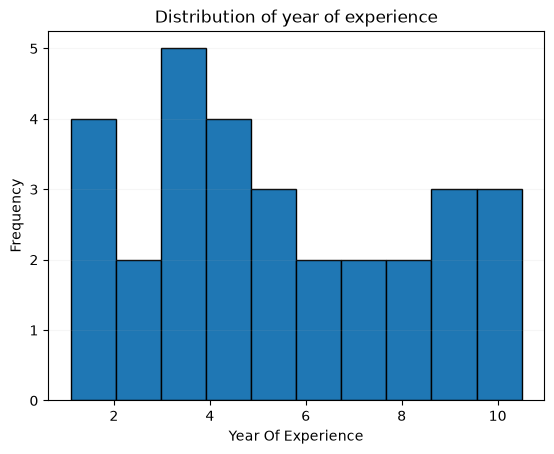

In [ ]:
plt.Figure(figsize=(10,6))

plt.hist(df["YearsExperience"],bins=10, edgecolor="black")

plt.title("Distribution of year of experience")
plt.xlabel("Year Of Experience")
plt.ylabel("Frequency")


plt.grid(axis="y",alpha=0.5)
plt.show()





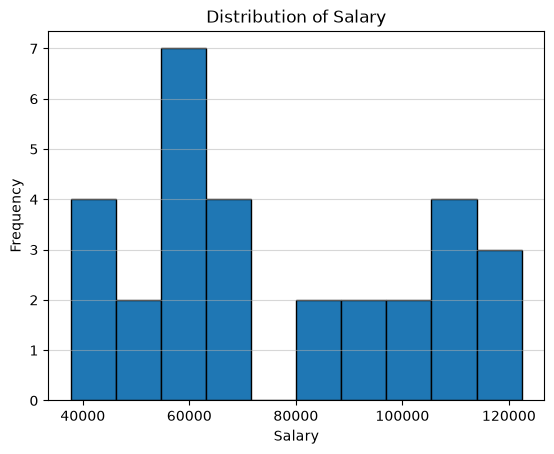

In [49]:

plt.Figure(figsize=(10,6))
plt.hist(df["Salary"],bins=10,edgecolor="Black")

plt.title("Distribution of Salary")
plt.xlabel("Salary")
plt.ylabel("Frequency")


plt.grid(axis="y",alpha=0.5)
plt.show()


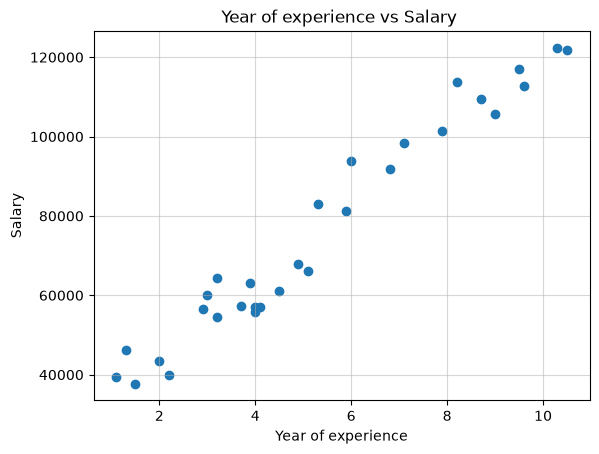

In [56]:
plt.Figure(figsize=(8,6))

plt.scatter(df["YearsExperience"],df["Salary"],marker="o")

plt.title("Year of experience vs Salary ")
plt.xlabel("Year of experience")
plt.ylabel("Salary")

plt.grid(True,alpha=0.5)
plt.show()



Separate features and labels

In [65]:
x=df[["YearsExperience"]]
y=df["Salary"]

print("Features(x)  :")
print(x.head())

print("Labels/Targets(y)  :")
print(y.head())


Features(x)  :
   YearsExperience
0              1.1
1              1.3
2              1.5
3              2.0
4              2.2
Labels/Targets(y)  :
0    39343
1    46205
2    37731
3    43525
4    39891
Name: Salary, dtype: int64


Split dataset in training and testing model

We will use 80% of our data for training model
        and 20% of our data for testing model .


In [67]:
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=.8,random_state=42)

print("Training Feature of x  :",x_train.shape)
print("Testing Feature of x   :",x_test.shape)
print("Training Feature of y  :",y_train.shape)
print("Testing Feature of y   :",x_test.shape)


Training Feature of x  : (24, 1)
Testing Feature of x   : (6, 1)
Training Feature of y  : (24,)
Testing Feature of y   : (6, 1)


Create and train the regression model

In [68]:

model = LinearRegression()
model.fit(x_train,y_train)

print("Traning model completed")



Traning model completed


Regression equation

In [71]:

slope = model.coef_[0]
intercept=model.intercept_

print("Slope      :",slope)
print("Intercept  :",intercept)

print("The Regression equation will be :")
print(f"salary={slope:.2f}*experience + {intercept:.2f}")

Slope      : 9423.815323030976
Intercept  : 25321.583011776813
The Regression equation will be :
salary=9423.82*experience + 25321.58


make Predictions

In [80]:
y_pred=model.predict(x_test)

pred_df=pd.DataFrame({
    "Experience" : x_test["YearsExperience"].values ,
    "Actual Salary" : y_test.values ,
    "Predict Salary" : y_pred
})

pred_df=pred_df.sort_values(by="Experience").reset_index(drop=True)

pred_df

,Experience,Actual Salary,Predict Salary
0,3.2,64445,55477.792045
1,3.7,57189,60189.699707
2,4.9,67938,71498.278095
3,5.3,83088,75267.804224
4,8.2,113812,102596.868661
5,9.6,112635,115790.210113


In [86]:
new_experience=pd.DataFrame({
    "YearsExperience":[5]
})

predict_salary=model.predict(new_experience)

print(f"Experience        :{new_experience['YearsExperience'].iloc[0]} years")
print(f"Predicted Salary  :{predict_salary[0]:.2f} ")



Experience        :5 years
Predicted Salary  :72440.66 


Visualize the Linear Regression Line

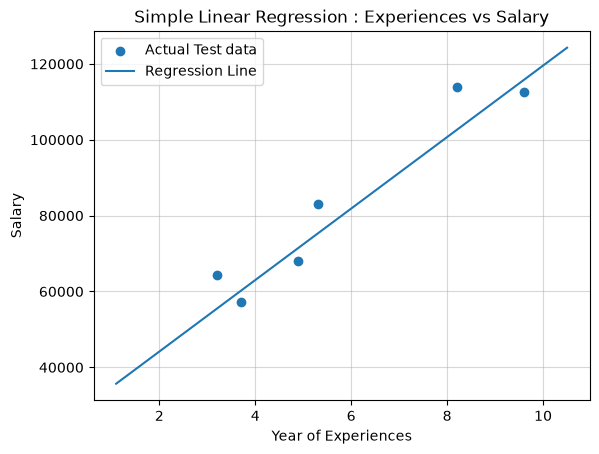

In [91]:
x_line=pd.DataFrame({
    "YearsExperience": np.linspace(
                        df["YearsExperience"].min() , 
                        df["YearsExperience"].max(),
                        200)
})

y_line=model.predict(x_line)
plt.Figure(figsize=(10,6))

plt.scatter(x_test['YearsExperience'],y_test,label="Actual Test data")
plt.plot(x_line["YearsExperience"],y_line,label="Regression Line")

plt.title("Simple Linear Regression : Experiences vs Salary")
plt.xlabel("Year of Experiences")
plt.ylabel("Salary")

plt.legend()
plt.grid(True,alpha=0.5)

plt.show()


Evaluate the model

In [97]:
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

print("The evalution of the model")
print(f"mae :{mae:.2f}")
print(f"mse :{mse:.2f}")
print(f"rmse :{rmse:.2f}")
print(f"r2 :{r2:.2f}")


The evalution of the model
mae :6286.45
mse :49830096.86
rmse :7059.04
r2 :0.90


Actual vs Predict Salary

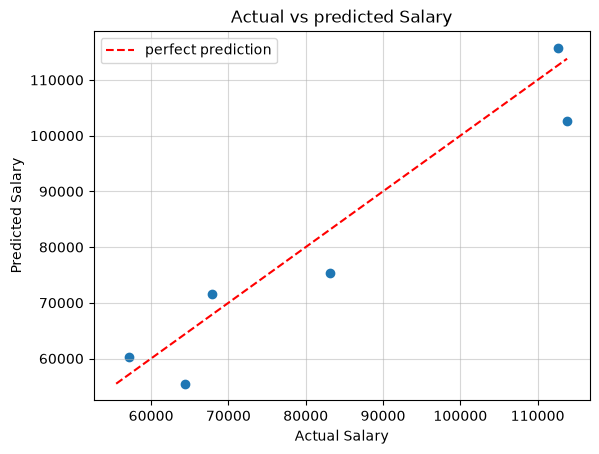

In [102]:
plt.Figure(figsize=(10,6))
plt.scatter(y_test,y_pred,marker="o")

min_val=min(y_pred.min(),y_test.min())
max_val=min(y_pred.max(),y_test.max())

plt.plot(
    [min_val,max_val] ,
    [min_val,max_val] , 
    linestyle="--" ,
    color="red",
    label="perfect prediction"
)

plt.title("Actual vs predicted Salary")
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")

plt.grid(True,alpha=0.5)
plt.legend()
plt.show()

Residual Analysis

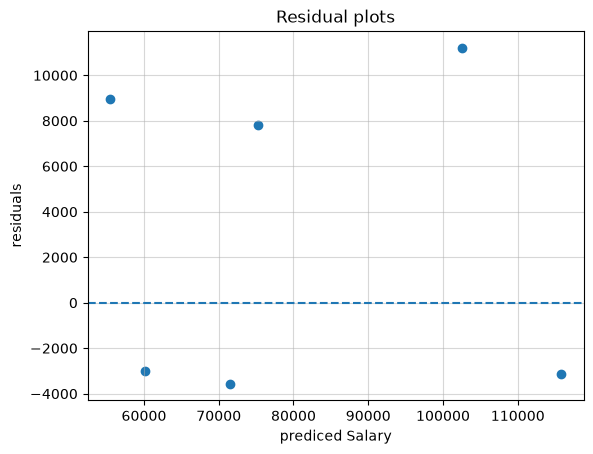

In [104]:
plt.Figure(figsize=(10,6))


residual=y_test-y_pred
plt.scatter(y_pred,residual)

plt.axhline(y=0,linestyle="--")

plt.title("Residual plots")
plt.xlabel("prediced Salary")
plt.ylabel("residuals")

plt.grid(True,alpha=0.5)
plt.show()

## Conclusion

In this project, I implemented Simple Linear Regression to analyze the relationship between years of work experience and salary.

I performed data inspection, preprocessing, exploratory data analysis, feature-target separation, and training-testing split. I trained the model using Scikit-learn's LinearRegression and used it to predict salaries for unseen data.

I evaluated the model using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² score. I also visualized the regression line, compared actual and predicted salaries, and analyzed the residuals.

The project helped me understand how a regression model learns relationships between numerical variables, how it makes predictions, and how its performance can be evaluated.

**Limitation:** Salary is influenced by many factors besides experience, such as education, job role, industry, location, and skills. Therefore, experience alone cannot explain every salary difference. The model also assumes a linear relationship and may not perform well outside the range of experience represented in the dataset.